# 02 · Exploratory Data Analysis

Which customers churn? Every plot ends with a one-line, stakeholder-ready insight.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import seaborn as sns
from src.data_cleaning import load_clean
from src.features import add_features

sns.set_theme(style='whitegrid')
FIG_DIR = ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = add_features(load_clean())
OVERALL = df['Churn'].mean()
print(f"Overall churn rate: {OVERALL:.1%}")

Overall churn rate: 26.5%


In [2]:
def churn_bar(col, ax, order=None):
    rate = df.groupby(col)['Churn'].mean().mul(100)
    rate = rate.reindex(order) if order else rate.sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color='#4C72B0')
    ax.axhline(OVERALL * 100, color='tab:red', ls='--', lw=1, label=f'overall {OVERALL:.0%}')
    ax.bar_label(ax.containers[0], fmt='%.0f%%')
    ax.set(xlabel='', ylabel='Churn rate (%)', title=f'Churn rate by {col}')
    ax.legend()
    return rate

## 1. Contract type

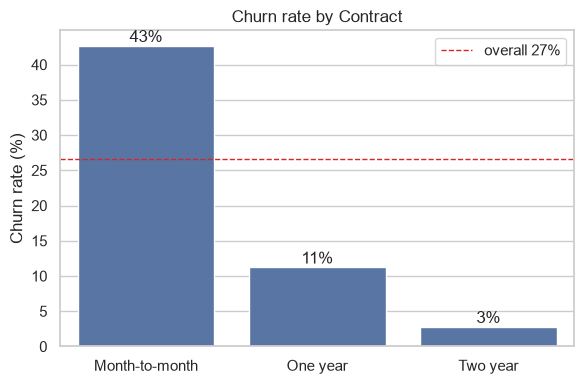

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
churn_bar('Contract', ax, order=['Month-to-month', 'One year', 'Two year'])
fig.tight_layout(); fig.savefig(FIG_DIR / 'churn_by_contract.png', dpi=150); plt.show()

> **Insight:** Month-to-month customers churn at **~43%**, versus 11% on one-year and 3% on two-year contracts. Nudging customers onto longer contracts is the biggest retention lever.

## 2. Tenure

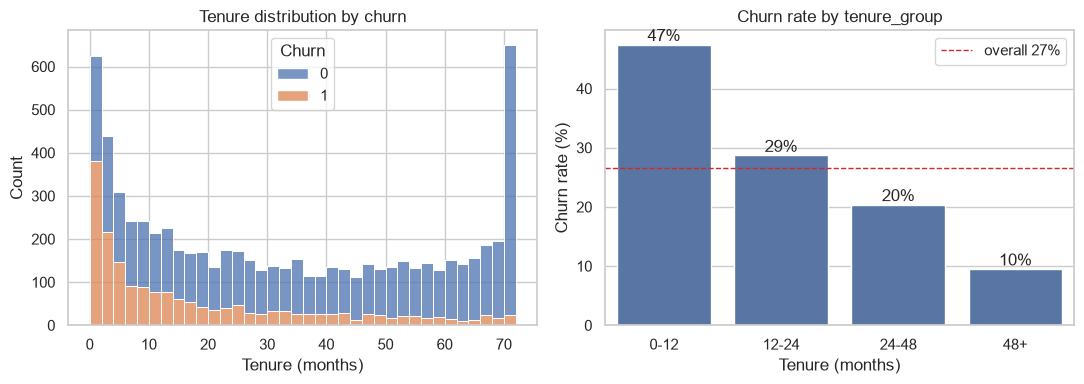

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x='tenure', hue='Churn', bins=36, multiple='stack', ax=axes[0])
axes[0].set(title='Tenure distribution by churn', xlabel='Tenure (months)')
churn_bar('tenure_group', axes[1], order=['0-12', '12-24', '24-48', '48+'])
axes[1].set_xlabel('Tenure (months)')
fig.tight_layout(); fig.savefig(FIG_DIR / 'churn_by_tenure.png', dpi=150); plt.show()

> **Insight:** Churn is concentrated in the **first year (47%)** and falls to 10% after four years (median tenure: 10 months for churners vs 38 for customers who stay). Onboarding and early-life engagement matter most.

## 3. Internet service & payment method

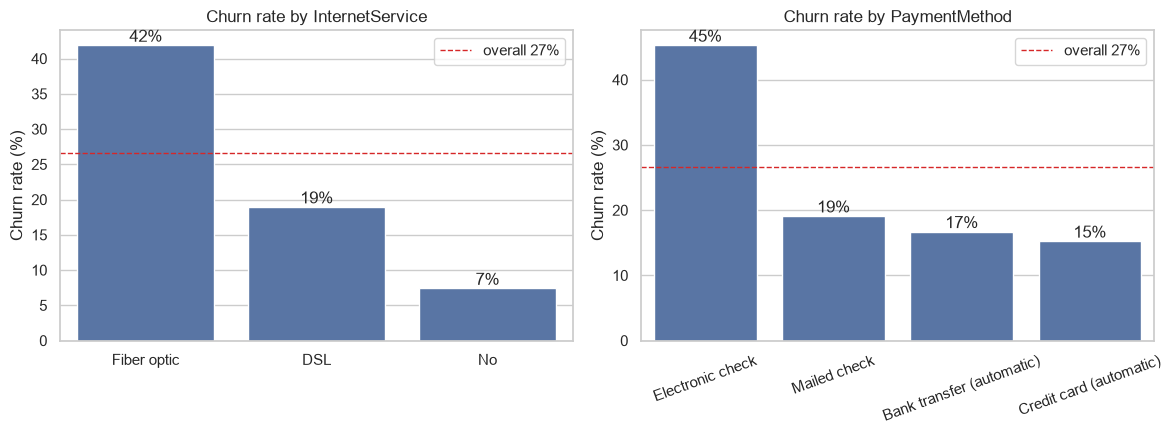

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
churn_bar('InternetService', axes[0])
churn_bar('PaymentMethod', axes[1])
axes[1].tick_params(axis='x', rotation=20)
fig.tight_layout(); fig.savefig(FIG_DIR / 'churn_by_internet_payment.png', dpi=150); plt.show()

> **Insight:** **Fiber-optic** customers churn at 42% (vs 19% on DSL), which points to a price or quality issue with the premium product. **Electronic-check** payers churn at 45%, about 3× the rate of customers on automatic payments. Promoting auto-pay is a cheap intervention.

## 4. Monthly charges

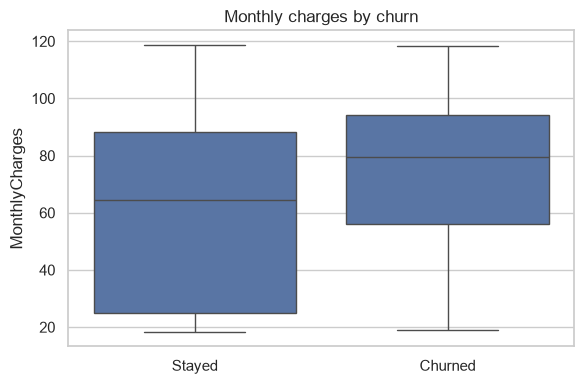

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=ax)
ax.set(xticks=[0, 1], xticklabels=['Stayed', 'Churned'], xlabel='', title='Monthly charges by churn')
fig.tight_layout(); fig.savefig(FIG_DIR / 'monthly_charges.png', dpi=150); plt.show()

> **Insight:** Churners pay more per month (median **\$80 vs \$64**). High bills combined with no long-term commitment is the classic at-risk profile.